<a href="https://colab.research.google.com/github/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting/blob/main/Chapter03_Zero_Shot_Forecasting/07a_zero_shot_toto2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 07a · Zero-shot forecasting with Toto-2.0

*Hands-On Open-Source Foundation Models for Time Series Forecasting*, Chapter 3: Zero-Shot Forecasting in Practice

This notebook runs Datadog's Toto-2.0 (22m) zero-shot: the models forecast our series straight away, without any training on
our data. Each model forecasts every dataset, every horizon (7, 14, 30, 60 and 90 days (D1, D2) and 3, 6, 9, 12 and 24 months (D3, D4)) and every rolling window fixed in
Notebook 04.

For each model you will find a figure of its architecture, a plain description of how it works and what is new
about it, what it costs to run, and which covariates it can read without fine-tuning. The figures were checked
against each model's paper, its released configuration and the network as loaded.

#### Why these models share a notebook

They install into the same Python environment (`requirements/env-toto2.txt`). Foundation-model libraries pin
different versions of `torch`, `numpy` and `transformers`, and these often clash, so the chapter groups the models
by the environment they need rather than by the company that made them.

The datasets are D1 (daily Central England temperature), D2 (D1 with 12 covariates), D3 (five monthly metal prices) and D4 (D3 with three global drivers, each known up to the forecast origin). The bonus datasets B1 and B2 have their own notebook: [bonus/B07a_zero_shot_toto2.ipynb](bonus/B07a_zero_shot_toto2.ipynb).

**What you will learn**

- what is inside each model, drawn layer by layer in one consistent style, with the maths of each layer explained
- which models can use past-only and known-future covariates without fine-tuning, and how they do it
- how the models' point forecasts compare across datasets and horizons, by MASE and by RMSE, and what they cost
  to run on a CPU
- how the forecasts look against the actual values at every horizon

| Environment and compute | |
|---|---|
| Python | 3.12 (tested); see *How to run* for Colab |
| Packages | [`requirements/env-toto2.txt`](requirements/env-toto2.txt) (pinned) |
| Hardware | CPU only; a GPU is used automatically if present |
| Network | downloads the checkpoints from Hugging Face on first use |
| Run time, quick check (default) | about 0.2 s of forecasting on 4 CPU cores (Colab's free tier has 2 cores: allow about twice as long) |
| Run time, `FULL_RUN = True` | about 1.2 s of forecasting with one CPU thread, while other notebooks shared the machine |
| Peak memory | 0.0 GB above the kernel's baseline (largest single call) |

**How to run this notebook**

- **Google Colab:** choose *Runtime > Run all*. The first code cell fetches this chapter's folder and installs `requirements/env-toto2.txt`
  with uv (a few minutes the first time). If it says it is restarting the session, wait, then choose *Runtime > Run all*
  again. To use your own copy on Google Drive, set `DRIVE_COPY` in that cell to the folder's path. A GPU runtime
  is not needed; if you pick one, the models use it.
- **Your own computer (Cursor, VS Code or Jupyter):** create the environment once with
  `uv venv .venv-toto2 -p 3.12 && uv pip install -p .venv-toto2 -r requirements/env-toto2.txt`
  (or `python3.12 -m venv .venv-toto2` and `pip install -r ...`), open this folder, choose the `.venv-toto2` kernel
  and run all cells.

In [1]:
# Setup: find this chapter's folder (on Colab: fetch it and install this notebook's environment)
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules


def is_chapter(d):
    return (Path(d) / "src" / "ch03_dataprep" / "__init__.py").is_file()


if IN_COLAB:  # get this chapter's folder and install this notebook's environment
    import shutil

    CHAPTER = "Chapter03_Zero_Shot_Forecasting"   # this chapter's folder in the book's repository
    DRIVE_COPY = ""   # optional: path of your own copy of this folder on Google Drive (skips GitHub)
    BOOK = Path("/content/book")

    def chapter_dir():  # this chapter's folder under /content/book, or None until it is there
        return next((d for d in (BOOK / CHAPTER, BOOK) if is_chapter(d)), None)

    def find_in_drive(top="/content/drive/MyDrive", depth=6):  # the copies of CHAPTER, shallowest first
        level = [top]
        for _ in range(depth):
            subdirs = []
            for d in level:
                try:
                    subdirs += [e.path for e in os.scandir(d) if e.is_dir() and not e.name.startswith(".")]
                except OSError:
                    pass
            hits = [d for d in subdirs if Path(d).name == CHAPTER and is_chapter(d)]
            if hits:
                return hits
            level = subdirs
        return []

    def local_only(d, names):  # what not to copy from Drive: local environments, caches, downloaded data
        return [n for n in names if n.startswith(".venv") or n == "__pycache__" or (d.endswith("/data") and n == "raw")]

    if chapter_dir() is None and not DRIVE_COPY:    # 1) clone the book's repository from GitHub
        shutil.rmtree(BOOK, ignore_errors=True)
        !GIT_TERMINAL_PROMPT=0 git clone -q --depth 1 https://github.com/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting /content/book
    if chapter_dir() is None:                       # 2) not on GitHub (yet): copy it from your Google Drive
        from google.colab import drive
        drive.mount("/content/drive")
        if not DRIVE_COPY:
            print(f"{CHAPTER} is not on GitHub: searching My Drive for it (set DRIVE_COPY above to skip this)")
            hits = find_in_drive()
            if len(hits) > 1:
                raise FileExistsError(f"several copies of {CHAPTER} in My Drive: {hits}. Set DRIVE_COPY to one.")
            DRIVE_COPY = hits[0] if hits else ""
        if DRIVE_COPY and not is_chapter(DRIVE_COPY):
            raise FileNotFoundError(f"DRIVE_COPY = {DRIVE_COPY!r} is not this chapter's folder (no src/ch03_dataprep)")
        if DRIVE_COPY:
            print(f"copying {DRIVE_COPY} to {BOOK / CHAPTER} ...")
            shutil.rmtree(BOOK, ignore_errors=True)
            shutil.copytree(DRIVE_COPY, BOOK / "partial-copy", ignore=local_only)
            (BOOK / "partial-copy").rename(BOOK / CHAPTER)    # only a finished copy gets the chapter's name
            print(f"copied {sum(len(files) for _, _, files in os.walk(BOOK / CHAPTER)):,} files")
    if chapter_dir() is None:
        raise FileNotFoundError(f"{CHAPTER} is not in the book's GitHub repository or in your Google Drive. "
                                "Upload the folder to Drive, or set DRIVE_COPY above to its path there.")
    os.chdir(chapter_dir())
    import importlib.metadata as md

    def key(name):  # package installers treat huggingface_hub and huggingface-hub as one package
        return name.lower().replace("_", "-").replace(".", "-")

    def versions():  # the version of every installed package, as Python finds it (first copy on sys.path)
        found = {}
        for d in md.distributions():
            found.setdefault(key(d.metadata["Name"]), d.version)
        return found

    before = versions()
    # Install with uv: it downloads and installs packages in parallel, several times faster than pip. Colab comes
    # with uv (installed here if not). The settings point uv at Colab's own Python (Colab has no virtual environment)
    # and drop install constraints that Colab may have left over from building its image. Each uv line falls back
    # to pip if uv fails.
    if shutil.which("uv") is None:
        %pip install -q uv
    for name in ("UV_CONSTRAINT", "UV_BUILD_CONSTRAINT", "UV_PRERELEASE"):
        os.environ.pop(name, None)
    os.environ.update(UV_PYTHON=sys.executable, UV_SYSTEM_PYTHON="1", UV_BREAK_SYSTEM_PACKAGES="1")
    # keep Colab's own torch (with CUDA) and Jupyter; install everything else this notebook needs
    !grep -vE "^(torch|jupyter|ipykernel|nbclient|nbformat|pytest|nbval|ruff)==" requirements/env-toto2.txt > /tmp/requirements-colab.txt
    !uv pip install -q -r /tmp/requirements-colab.txt || {sys.executable} -m pip install -q -r /tmp/requirements-colab.txt
    # stop here if neither uv nor pip could install everything; the error message is above
    try:
        from packaging.version import Version
    except ImportError:
        Version = str
    missing = []
    for line in open("/tmp/requirements-colab.txt"):
        name, _, pin = line.split("#")[0].strip().partition("==")
        if not pin:
            continue
        try:
            installed = md.version(name.split("[")[0])
        except md.PackageNotFoundError:
            installed = None
        if installed is None or Version(installed) != Version(pin):
            missing.append(f"{name}=={pin}")
    if missing:
        raise RuntimeError(f"Could not install {', '.join(missing)}; scroll up for its error. If it was a network error, "
                           "run this cell again. If uv or pip tried to build a package from source, this runtime's Python is "
                           "too new for this notebook: see the How to run section at the top.")
    # Colab comes with torchvision, torchaudio, torchcodec and transformers, and torchmetrics imports some of them
    # whenever they are installed. If the install changed a package they depend on (some environments replace torch or
    # huggingface-hub), they no longer load. This notebook does not need them, so remove those that broke.
    try:
        from packaging.requirements import Requirement
    except ImportError:  # Colab has packaging; pip always carries its own copy
        from pip._vendor.packaging.requirements import Requirement

    now = versions()
    changed = {name for name, version in now.items() if before.get(name) != version}
    if "torch" in changed:
        # This notebook needs another torch than Colab's (Notebook 06: 2.4.1). Replacing torch can leave some of the
        # old torch's files behind, and Python then loads them ("cannot import name ... from torch.onnx"). Reinstall
        # it into clean folders (uv takes it from its cache, so nothing downloads twice).
        print(f"Replacing Colab's torch {before.get('torch')} with {now['torch']}: reinstalling it into clean folders ...")
        torch_pin = now["torch"]
        site = Path(md.distribution("torch").locate_file(""))
        folders = [site / m for m, names in md.packages_distributions().items()
                   if "torch" in names and m.isidentifier() and (site / m).is_dir()]
        !uv pip uninstall -q torch || {sys.executable} -m pip uninstall -q -y torch
        for folder in folders:
            shutil.rmtree(folder, ignore_errors=True)
        !uv pip install -q torch=={torch_pin} || {sys.executable} -m pip install -q torch=={torch_pin}
        now = versions()

    def requirements(dist):  # the requirements of an installed package that apply here
        found = []
        for line in md.requires(dist) or []:
            try:
                r = Requirement(line)
                if r.marker is None or r.marker.evaluate({"extra": ""}):
                    found.append(r)
            except Exception:  # a line this version of packaging cannot read
                pass
        return found

    def broken(dist):  # Colab's copy of dist, and the install changed something it needs
        if dist not in now or dist in changed:
            return False  # not installed, or installed by this notebook
        if "torch" in changed:
            return True   # Colab built and tested it with its own torch
        return any(key(r.name) in changed and not r.specifier.contains(now[key(r.name)], prereleases=True)
                   for r in requirements(dist))

    misfits = [d for d in ("torchvision", "torchaudio", "torchcodec", "transformers") if broken(d)]
    if misfits:
        print(f"Removing unused packages that this install broke: {', '.join(misfits)}")
        !uv pip uninstall -q {" ".join(misfits)} || {sys.executable} -m pip uninstall -q -y {" ".join(misfits)}
    # Colab imports some packages (numpy, pandas, torch, ...) before this cell finishes. If the install replaced one
    # of them, Python keeps the old version in memory and mixes it with the new files on disk (errors such as
    # "cannot import name ... from torch.onnx"), so restart once to load the new version.
    after = versions()
    stale = sorted(m for m, names in md.packages_distributions().items() if m in sys.modules
                   and any(before.get(key(n), after.get(key(n))) != after.get(key(n)) for n in names))
    for m in ("torch", "numpy", "pandas", "scipy"):  # also catches a session that was not restarted after an earlier run
        loaded = str(getattr(sys.modules.get(m), "__version__", ""))
        if loaded and m not in stale and loaded.split("+")[0] != after.get(m, loaded).split("+")[0]:
            stale.append(m)
    restarted_from = Path("/tmp/ch03_restart_pid")   # the session this cell last asked to restart
    if stale and restarted_from.is_file() and restarted_from.read_text() == str(os.getpid()):
        raise SystemExit(f"The session has not restarted and still has the old {', '.join(stale)} in memory. "
                         "Choose Runtime > Restart session, then Runtime > Run all.")
    if stale:
        restarted_from.write_text(str(os.getpid()))
        print(f"The install updated {', '.join(stale)}, which Colab had already loaded: restarting the session.")
        from IPython import get_ipython
        kernel = getattr(get_ipython(), "kernel", None)
        if kernel is not None:
            kernel.do_shutdown(True)
        raise SystemExit("When the session has restarted, choose Runtime > Run all again; the first cell then finishes quickly. "
                         "If it has not restarted after a few seconds, choose Runtime > Restart session, then Runtime > Run all.")
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if is_chapter(p))
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)
DATA, RESULTS, INPUT = ROOT / "data", ROOT / "results", ROOT / "input_timeseries"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"chapter folder: {ROOT}  |  Python {sys.version.split()[0]}  |  Colab: {IN_COLAB}  |  device: {DEVICE}")

chapter folder: /home/user/fresh/repo/Chapter03_Zero_Shot_Forecasting  |  Python 3.12.13  |  Colab: False  |  device: cpu


#### Quick check or full run

With `FULL_RUN = False`, the default, each model makes a quick check: it forecasts the fixed-origin window at the
two shortest horizons of every dataset. That is enough to show that the model installs and runs on your machine.
The analysis then reads the stored results of the full runs (every horizon and every rolling window) from
`results/forecasts/`. Set `FULL_RUN = True` to recompute those full results yourself.

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from ch03_dataprep.plotting import set_style
from ch03_zeroshot.architectures import figure
from ch03_zeroshot.capabilities import capability_table
from ch03_zeroshot.data import load_frame
from ch03_zeroshot.models import get_model
from ch03_zeroshot.report import (cost_table, forecast_gallery, gain_tables, load_forecasts, run_table,
                                  scores_cached, show_forecast_tables, show_gains, show_horizon_table)
from ch03_zeroshot.metrics import aggregate
from ch03_zeroshot.runner import quiet_logs, run_model, run_summary
from ch03_zeroshot.tables import display_names

warnings.filterwarnings("ignore")
quiet_logs()   # keep the libraries' routine INFO messages out of the outputs; warnings still show
set_style()
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)

FULL_RUN = False                       # True: recompute every horizon and window (see the table above)
MODELS = ['toto2']
DATASETS = ['D1', 'D2', 'D3', 'D4']
NAMES = display_names()
FIG = RESULTS / "figures" / "architectures"
FIG.mkdir(parents=True, exist_ok=True)


def forecast(key):
    """Run one model (quick check or full run) and show what it read and how long it took."""
    log = run_model(key, DATASETS, ROOT, smoke=not FULL_RUN, verbose=False)
    print(f"{log['name']} ({log['checkpoint']}): {(log['parameters'] or 0) / 1e6:.1f}M parameters, "
          f"loaded in {log['load_seconds']} s")
    return run_table(log, DATASETS)

## 1 · The models in this notebook

The table lists each model with the organisation that released it, the kind of network it is built on, its size
and the licence of its weights. A few terms come up again and again in the model descriptions that follow:

- A **token** is the piece of input a network handles as one unit. Most models cut a series into **patches**,
  short windows of consecutive values (16 or 32 steps, for example), and turn each patch into one token, so a long
  context becomes a short sequence.
- **Attention** lets every token look at the other tokens and take in the ones that matter for it. Its cost grows
  with the square of the number of tokens, which is why patching helps. **Recurrent** and **state-space** layers
  instead carry a running memory along the sequence, so their cost grows only in proportion to its length.
- An **encoder** reads the whole context at once. A **decoder-only** model, like the GPT language models, reads
  the tokens in time order and predicts what comes next.
- **Time attention** works along one series. **Variate attention** (also called group attention) works across the
  series at the same time step; that is how a model reads several targets, or a target and its covariates,
  together.
- A **quantile forecast** gives several values for each future step, for example the 10 %, 50 % and 90 %
  quantiles, instead of a single number. The median (the 50 % quantile) is the point forecast scored in this
  chapter.
- In the cost notes, $T$ is the context length, $H$ the horizon, $N$ the number of tokens, $d$ the width of a token
  vector, $L$ the number of layers and $V$ the number of rows (targets plus covariates). $O(N^2 d)$ means that
  doubling the number of tokens roughly quadruples the work.

| Model | Organisation | Backbone | Parameters | Checkpoint | Licence |
|---|---|---|---|---|---|
| Toto-2.0 (22m) | Datadog | decoder-only, time + variate attention | 21.9M | `Datadog/Toto-2.0-22m` | Apache-2.0 |

In [3]:
capability_table().set_index("key").loc[MODELS, ["model", "multivariate", "past_covariates", "future_covariates",
                                                 "exogenous_class", "how"]]

,model,multivariate,past_covariates,future_covariates,exogenous_class,how
key,,,,,,
toto2,Toto-2.0 (22m),True,False,False,none (target only),joint targets via variate attention; exogenous...


## 2.1 · Toto-2.0 (22m) (Datadog)

Toto 2.0 keeps the decoder of Toto, with layers that alternate attention along time and across series. It replaces Toto's step-by-step sampling with contiguous patch masking, a nine-quantile output head and an arcsinh input scaler. The 22m checkpoint has five time layers and one variate layer.

#### How to read the figure

Read the figure from left to right. Its four numbered panels follow the data from the series the model reads to the forecast it returns. The bold sentence under the panels sums up what sets the model apart, and the grey lines below give its size and main settings, then how this chapter's notebooks run it.

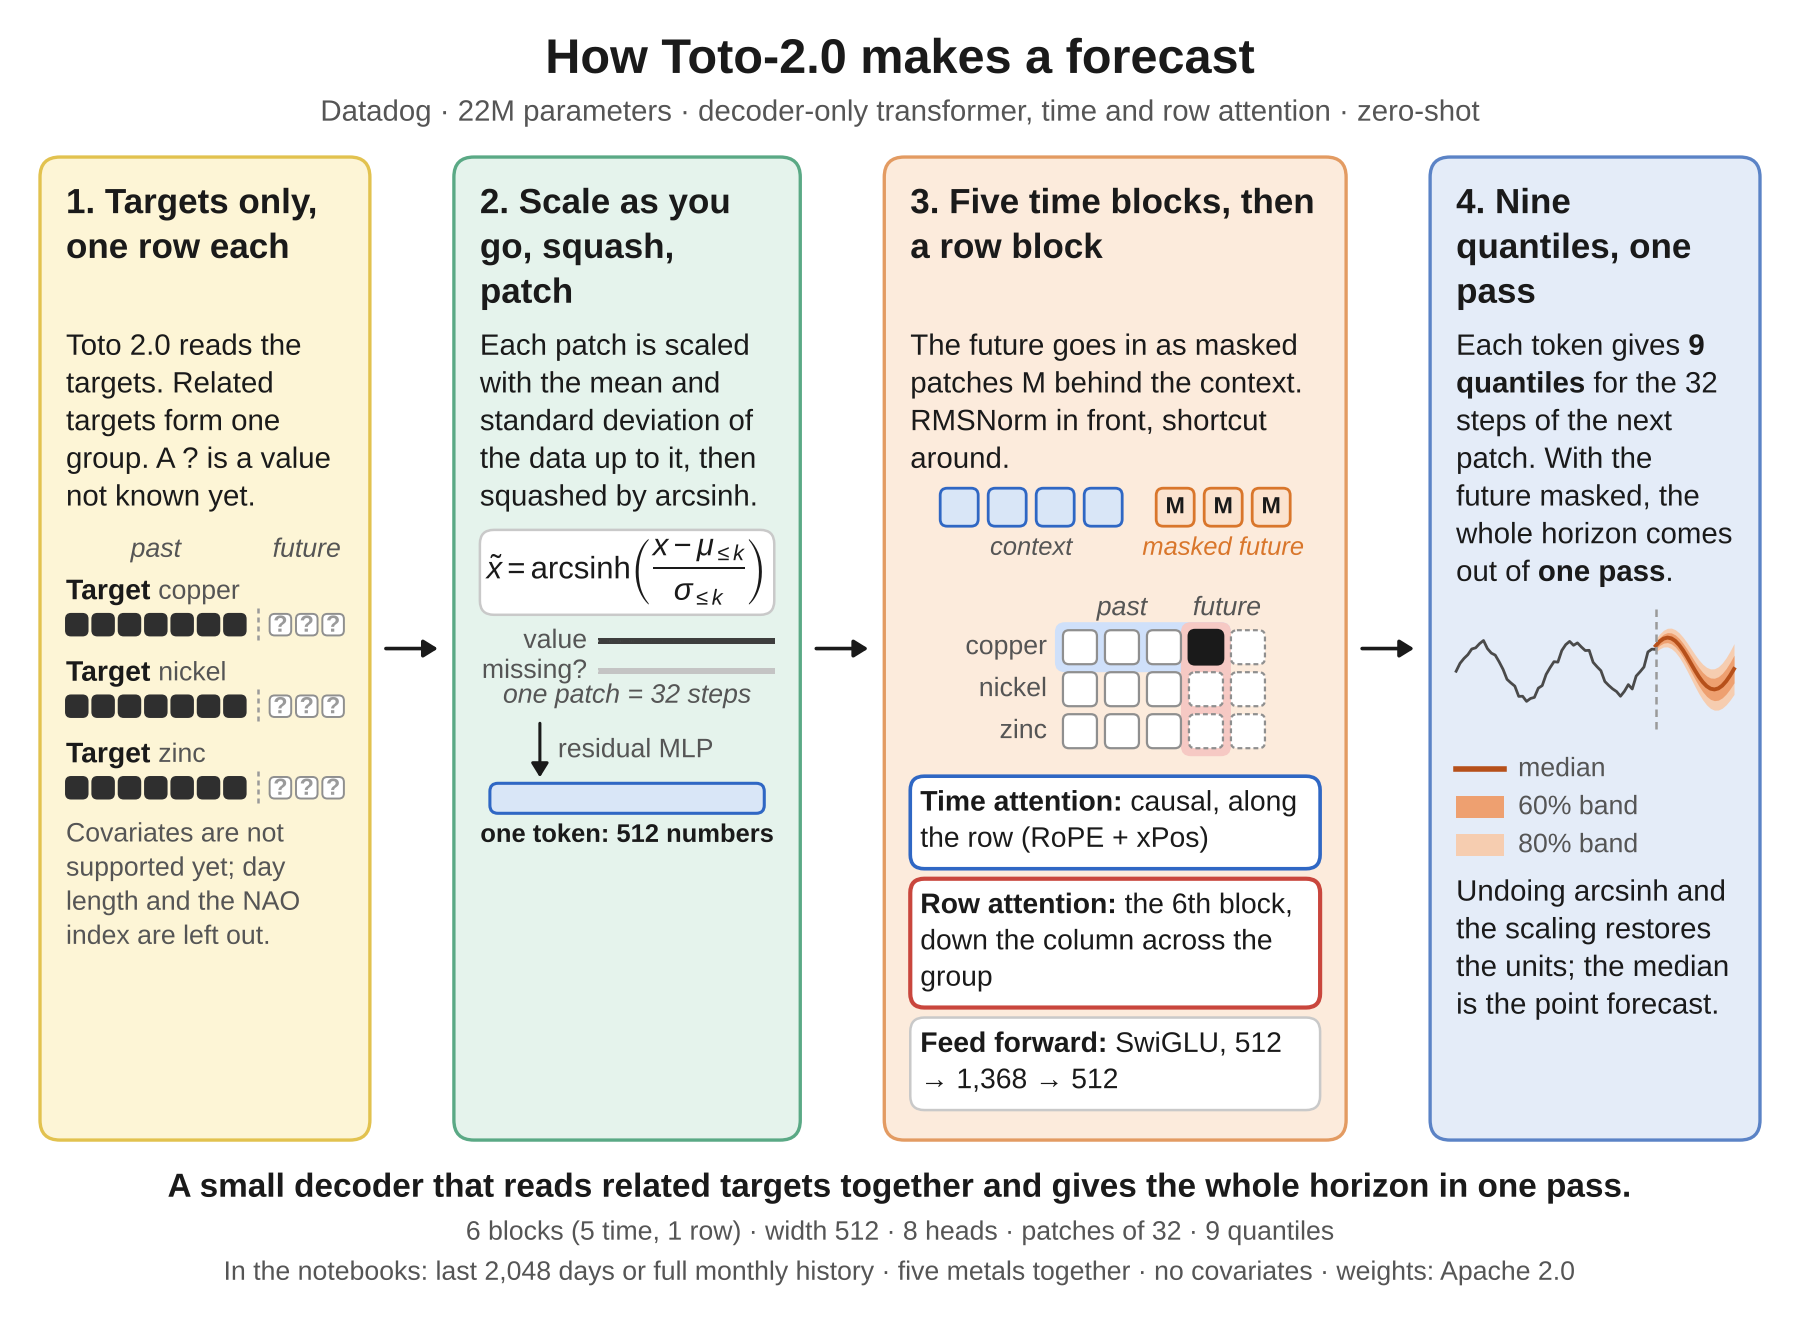

In [4]:
fig = figure("toto2", path=FIG / "toto2.png")

#### The maths behind the figure

The figure names the model's main components. Their equations follow, in the order in which the data passes through them.

The input is first **standardised** with the mean $\mu$ and standard deviation $\sigma$ of the context (in the causal versions, of the values seen so far), and then compressed with the **inverse hyperbolic sine** (arcsinh):

$$\tilde{x}_ t=\mathrm{arcsinh}\left(\frac{x_t-\mu}{\sigma}\right)$$

The arcsinh is close to a straight line near zero and grows like a logarithm for large values, so a few spikes cannot dominate the input.

**Patching** cuts the series into windows of $P$ steps, and each window becomes one token:

$$p_i=(\tilde{x}_ {(i-1)P+1},\dots,\tilde{x}_ {iP})$$

A context of $T$ steps then gives $T/P$ tokens, so attention costs $(T/P)^2$ instead of $T^2$.

The **patch embedding** turns each patch (with its missing-value mask, where the model has one) into a vector of width $d$, the token the transformer works on:

$$h_i=\mathrm{MLP}(p_i)$$

The map is a small fully connected network, a multilayer perceptron (MLP).

The **quantile head** has one output per quantile level $\tau$. Training minimises the pinball loss $\rho_\tau$ of the error $u=y-\hat{q}_ \tau$:

$$\rho_\tau(u)=\max(\tau u,\thinspace(\tau-1)u)$$

Minimising this loss makes each output the $\tau$-quantile of the forecast distribution. The median ($\tau=0.5$) is the point forecast scored in this chapter.

**RMSNorm** divides each token vector $h$ by its root mean square and multiplies the result by a learned gain $g$:

$$\frac{h}{\sqrt{\frac{1}{d}\sum_j h_j^2+\epsilon}}\odot g$$

Here $d$ is the width of the vector and $\epsilon$ a small constant that avoids dividing by zero. The normalisation keeps the size of the activations stable through many layers.

Toto-2.0's **attention** multiplies the queries by a learned per-dimension scale $s$ (PerDimScale) and divides the scores by $d_k$ rather than $\sqrt{d_k}$:

$$\mathrm{softmax}\left(\frac{(s\odot Q)K^{\top}}{d_k}+M\right)V$$

This is the scaling of μP (maximal update parametrisation), which keeps the scores stable as the network gets wider. $M$ is causal in time attention; variate attention has no mask.

The **SwiGLU feed-forward network** passes one projection of the token through SiLU and uses it to gate a second projection, element by element ($\odot$), before projecting back:

$$W_2\left(\mathrm{SiLU}(W_1h)\odot W_3h\right)$$

It trains better than a plain ReLU network of the same size.

#### What it costs to run

The time layers cost O(V · N² · d) and the variate layer O(N · V² · d), with N = T/32. The loaded network has 21.9M parameters.

#### Covariates

Without fine-tuning, Toto-2.0 (22m) can forecast several target series jointly. It reads no covariates. Variate attention runs across the target series; covariates are not yet supported.

#### Where the figure comes from

The figure was checked against the model's paper, its released code and configuration, and the code this chapter
runs. The main sources for its components:

| Component in the figure | Source |
|---|---|
| decoder-only, alternating time (causal) and variate (full) attention | Khwaja et al. 2026, Sec. 2 |
| contiguous patch masking, quantile head, arcsinh scaler, residual MLP projections, PerDimScale | Sec. 2.1-2.4 |
| patch 32 | Sec. 2.4; config.json |
| 22m: 6 layers = 5 time + 1 variate, d_model 512, 8 heads, d_ff 1368 | config.json; module tree |

#### The code

This chapter's adapter for Toto-2.0 (22m) is the class `Toto2` in [`src/ch03_zeroshot/models/toto.py`](src/ch03_zeroshot/models/toto.py) (line 58): it loads the checkpoint [`Datadog/Toto-2.0-22m`](https://huggingface.co/Datadog/Toto-2.0-22m), hands the model our context (and the covariates it can read) and turns its output into quantiles. All adapters share the interface `ZeroShotForecaster` in [`models/base.py`](src/ch03_zeroshot/models/base.py), and `run_model` in [`runner.py`](src/ch03_zeroshot/runner.py) runs it over every dataset, horizon and window. The network itself, layer by layer, is implemented in the `toto-2` 2.0.0 library ([PyPI page](https://pypi.org/project/toto-2/2.0.0/)). The figure above is drawn by [`architectures.py`](src/ch03_zeroshot/architectures.py).

In [5]:
forecast("toto2")

Toto-2.0 (Datadog/Toto-2.0-22m): 21.9M parameters, loaded in 12.5 s


,status,seconds,covariates read,notes
dataset,,,,
D1,ran,0.1,none,
D2,D1 forecasts reused,0.0,none,"reads none of these covariates, so its input is exactly D1's"
D3,ran,0.1,none,
D4,D3 forecasts reused,0.0,none,"reads none of these covariates, so its input is exactly D3's"


## 3 · Results of the full runs

The tables below read the stored forecasts of every horizon and rolling window (or your own, after
`FULL_RUN = True`). The helper functions behind them (scores, tables, plots and gain tables) are in
[`src/ch03_zeroshot/report.py`](src/ch03_zeroshot/report.py), and the metrics in
[`metrics.py`](src/ch03_zeroshot/metrics.py).

Each model's point forecast is its median, or its mean for the models that output one. Two errors score it. The
**MASE** (mean absolute scaled error) divides the mean absolute error of the forecast by the mean absolute error
that a naive rule makes on the history up to the forecast origin $T$:

$$\mathrm{MASE} = \frac{\frac{1}{H}\sum_{h=1}^{H}\left|y_{T+h}-\hat y_{T+h}\right|}{\frac{1}{T-\ell}\sum_{t=\ell+1}^{T}\left|y_t-y_{t-\ell}\right|}.$$

The naive rule repeats the value from $\ell$ steps earlier: the same day last year for temperature ($\ell = 365$), and the last value for metal prices ($\ell = 1$).
A MASE below 1 means that the model's errors were smaller than the errors the naive rule made on the history. The
**RMSE**, the root mean squared error, squares the errors before averaging, so it punishes large misses more.

Notebook 11 adds more metrics and compares every model of the chapter. This section looks
only at the models of this notebook, next to the naive and seasonal naive forecasts.

#### MASE by dataset and horizon

The best value in each row is in bold.

On D2 and D4 a model that cannot read the covariates gets exactly its D1 or D3 input, so its rows there repeat its D1 or D3 rows (the naive and seasonal naive rules read no covariates at all).

In [6]:
fc = load_forecasts(ROOT, MODELS + ["naive", "snaive"], DATASETS)
agg = aggregate(scores_cached(ROOT, MODELS + ["naive", "snaive"], DATASETS))
show_horizon_table(agg, "MASE", MODELS + ["naive", "snaive"], NAMES)

#### RMSE by dataset and horizon

The same table for the root mean squared error. Squaring the errors before averaging makes the RMSE weigh large
misses more than the MASE does, so a model that is usually close but sometimes far off looks worse here. To average over the five metals, whose prices differ by a factor of about ten,
the mean squared error (MSE) of the forecast is divided by the mean squared error of the naive rule on the history,
and the square root of the ratio is taken. The result is the root mean squared scaled error (RMSSE), whose weighted
form was the accuracy metric of the M5 forecasting competition:

$$\mathrm{MSE} = \frac{1}{H}\sum_{h=1}^{H}\left(y_{T+h}-\hat y_{T+h}\right)^2, \qquad \mathrm{MSE}_ {\text{naive}} = \frac{1}{T-\ell}\sum_{t=\ell+1}^{T}\left(y_t-y_{t-\ell}\right)^2,$$

$$\mathrm{RMSSE} = \sqrt{\mathrm{MSE} / \mathrm{MSE}_ {\text{naive}}}.$$

Below 1 again means smaller errors than the naive rule made on the history. Notebook 11 shows
the RMSE in the units of the data for every series.

In [7]:
show_horizon_table(agg, "RMSSE", MODELS + ["naive", "snaive"], NAMES)

#### Actual values against the forecasts

There is one figure per dataset, with one row of panels per series (all five metals on D3 and D4) and one panel per horizon. Each
panel shows the recent history (grey), what actually happened (black) and the point forecast of each model, all from
the same test window. Window 1 is the most recent one and ends at the last observation, so the longer horizons
start further back in time. To show fewer series, change `SERIES` (for example to `"copper"` for one metal); to look at an older
window, change `WINDOW` (daily data has 5 rolling windows, monthly data 3, and 1 at 24 months). Only D1 and D3 are drawn: no model here reads covariates, so its D2 and D4 forecasts are the
same.

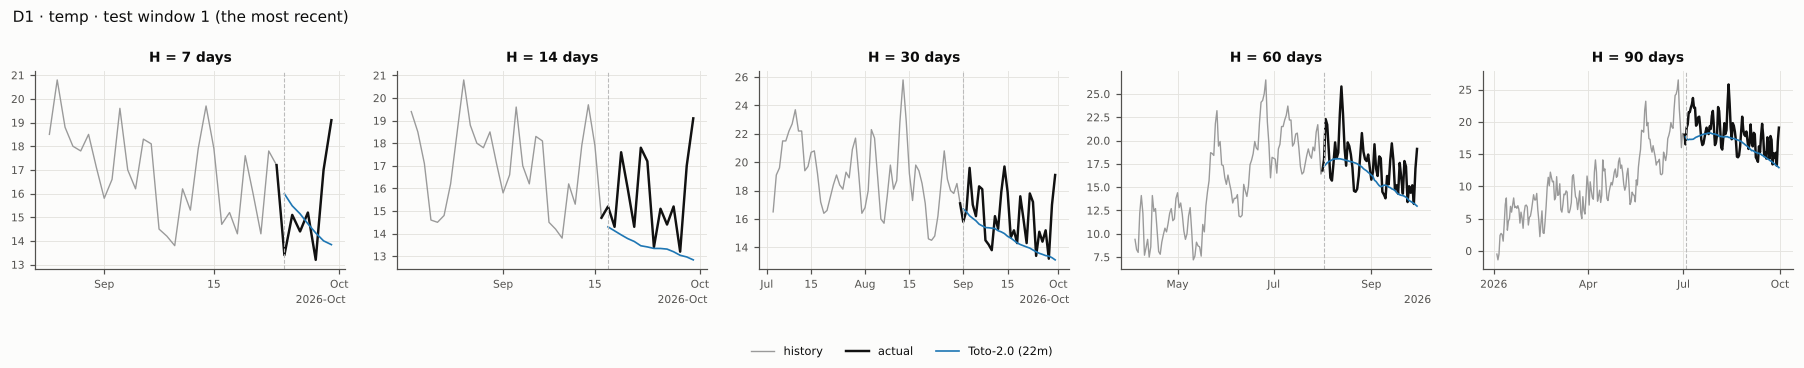

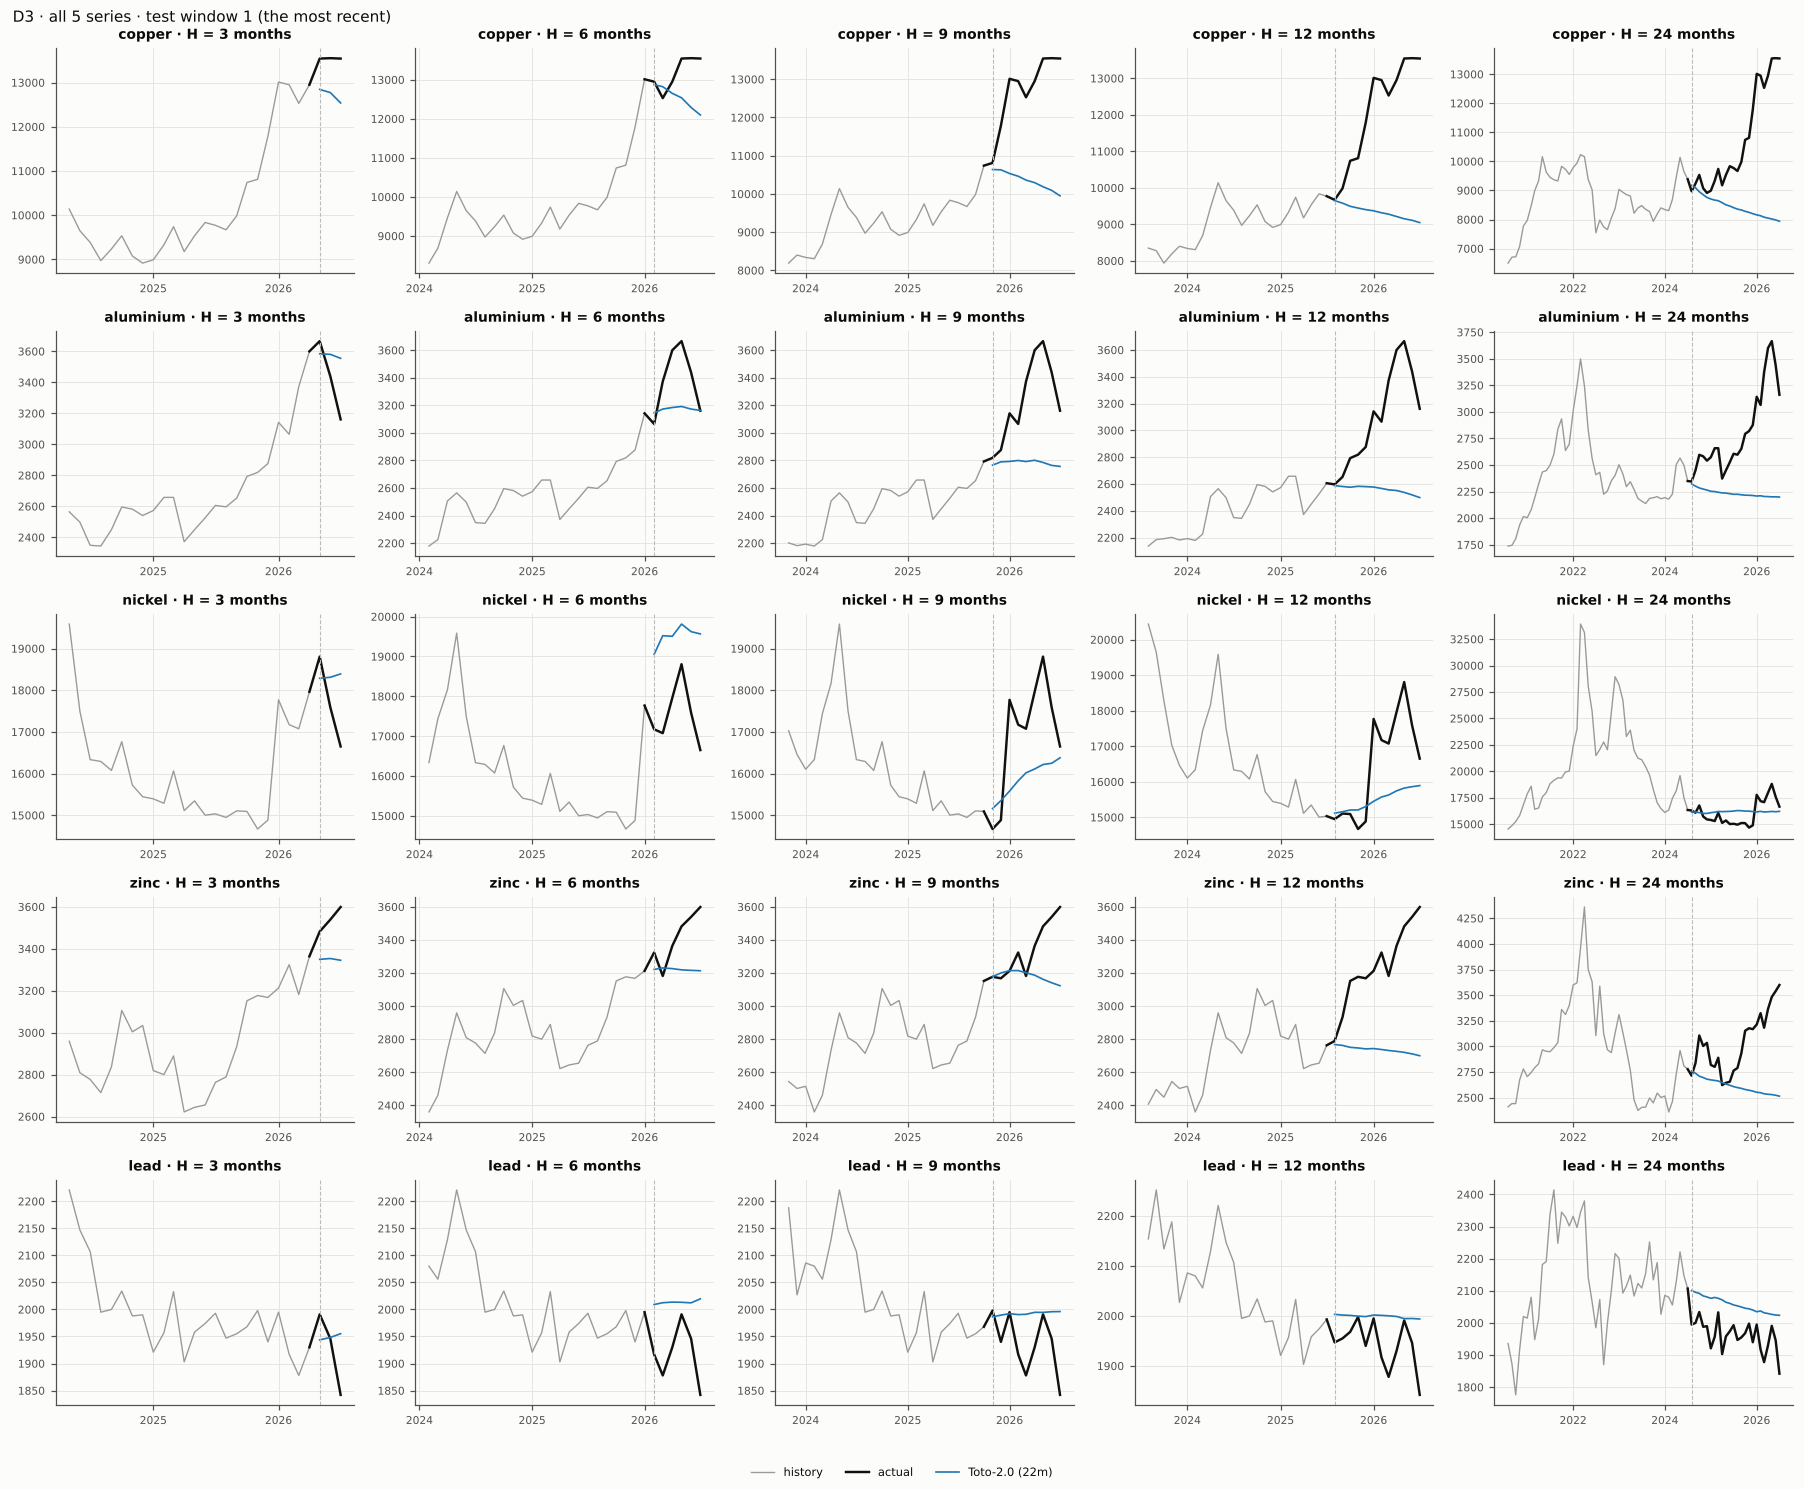

In [8]:
# the series to show: "all", one name or a list of names;
# D3 and D4 hold copper, aluminium, nickel, zinc and lead
SERIES = {"D1": "temp", "D2": "temp", "D3": "all", "D4": "all"}
WINDOW = 1  # 1 = the most recent test window
frames = {d: load_frame(ROOT, d) for d in ["D1", "D3"]}
figs = forecast_gallery(fc, frames, SERIES, MODELS, NAMES, window=WINDOW)

#### The forecasts in numbers

For each dataset, the table shows the actual values and every model's point forecast at one horizon of the same test window, with the naive and seasonal naive rules as baselines.
`SERIES` and `WINDOW` work as in the plots above, so there is one table per series; change `HORIZON` to see another
horizon. In each row the forecast closest to the actual value is in bold. The grey rows underneath summarise the
window: the MAE, the RMSE and the mean error ME = mean(actual − forecast), which is positive when the forecasts were
too low. The best value of each is in bold. One window is a small sample, so these numbers can rank the models
differently from the averages over all windows in the tables above. Every horizon of the window is saved as a CSV
file in `results/tables/forecast_vs_actual/`.

In [9]:
HORIZON = {"D1": 14, "D2": 14, "D3": 6, "D4": 6}   # D1, D2: 7, 14, 30, 60 or 90 days; D3, D4: 3, 6, 9, 12 or 24 months
show_forecast_tables(fc, SERIES, HORIZON, MODELS + ["naive", "snaive"], NAMES, window=WINDOW, datasets=list(frames),
                     save=RESULTS / "tables" / "forecast_vs_actual" / "07a.csv")

**D1 · temp · H = 14 days · test window 1** (2026-09-17 to 2026-09-30)

,actual,Toto-2.0 (22m),Naive (RW),Seasonal naive
2026-09-17,15.20,14.30,14.70,15.10
2026-09-18,14.30,14.12,14.70,17.70
2026-09-19,17.60,13.95,14.70,18.80
2026-09-20,16.00,13.78,14.70,15.90
2026-09-21,14.30,13.65,14.70,10.80
2026-09-22,17.80,13.46,14.70,9.30
2026-09-23,17.20,13.41,14.70,9.80
2026-09-24,13.40,13.34,14.70,12.10
2026-09-25,15.10,13.34,14.70,11.60
2026-09-26,14.40,13.31,14.70,10.80


**D3 · copper · H = 6 months · test window 1** (2026-02-01 to 2026-07-01)

,actual,Toto-2.0 (22m),Naive (RW),Seasonal naive
2026-02-01,"12,951","12,873","13,012","9,331"
2026-03-01,"12,529","12,822","13,012","9,740"
2026-04-01,"12,951","12,651","13,012","9,177"
2026-05-01,"13,543","12,538","13,012","9,533"
2026-06-01,"13,552","12,290","13,012","9,835"
2026-07-01,"13,543","12,097","13,012","9,771"
MAE,,731,368,"3,614"
RMSE,,901,427,"3,634"
ME (actual - forecast),,633,166,"3,614"


**D3 · aluminium · H = 6 months · test window 1** (2026-02-01 to 2026-07-01)

,actual,Toto-2.0 (22m),Naive (RW),Seasonal naive
2026-02-01,"3,065","3,145","3,142","2,658"
2026-03-01,"3,373","3,173","3,142","2,658"
2026-04-01,"3,600","3,184","3,142","2,372"
2026-05-01,"3,666","3,192","3,142","2,449"
2026-06-01,"3,439","3,173","3,142","2,526"
2026-07-01,"3,161","3,163","3,142","2,606"
MAE,,240,268,839
RMSE,,293,325,895
ME (actual - forecast),,212,242,839


... (3 outputs left out)

,actual,Toto-2.0 (22m),Naive (RW),Seasonal naive
2026-02-01,"3,324","3,221","3,213","2,800"
2026-03-01,"3,182","3,231","3,213","2,889"
2026-04-01,"3,364","3,226","3,213","2,622"
2026-05-01,"3,482","3,219","3,213","2,644"
2026-06-01,"3,539","3,216","3,213","2,655"
2026-07-01,"3,599","3,214","3,213","2,763"
MAE,,210,212,686
RMSE,,243,246,718
ME (actual - forecast),,194,202,686


**D3 · lead · H = 6 months · test window 1** (2026-02-01 to 2026-07-01)

,actual,Toto-2.0 (22m),Naive (RW),Seasonal naive
2026-02-01,"1,917","2,009","1,995","1,957"
2026-03-01,"1,878","2,012","1,995","2,033"
2026-04-01,"1,930","2,014","1,995","1,903"
2026-05-01,"1,991","2,013","1,995","1,958"
2026-06-01,"1,946","2,012","1,995","1,974"
2026-07-01,"1,842","2,020","1,995","1,993"
MAE,,96,78,72
RMSE,,108,91,92
ME (actual - forecast),,-96,-78,-52


Every horizon of window 1 saved to /home/user/fresh/repo/Chapter03_Zero_Shot_Forecasting/results/tables/forecast_vs_actual/07a.csv


#### Covariates

No model in this notebook reads covariates, so its D2 and D4 forecasts are its D1 and D3 forecasts. Notebook 11 compares the covariate gains, by MASE and by RMSE, of the models that do read them.

#### What the runs cost

The time spent forecasting, in seconds, over all horizons and rolling windows on 4 CPU cores. A value of 0.0 means that the model reads none of that dataset's covariates, so its D1 or D3 forecasts were reused.

In [10]:
runs = run_summary(ROOT, MODELS)
cost_table(runs, DATASETS)

dataset,D1,D2,D3,D4
model,,,,
Toto-2.0,0.7,0.0,0.5,0.0


## 4 · Key insights


- **Toto-2.0 is good on temperature, but not among the best.** Its mean MASE on D1 is 0.709, 17% below the seasonal
  naive forecast (0.858) and 5% above Chronos-Bolt (0.672). The gap is at short horizons (0.59 at 7 days against
  0.53 for Chronos-Bolt and Moirai-2.0); from 60 days on it is level with them (0.76 and 0.70).
- **On metals it trails the random walk at every horizon** (mean MASE 3.28 against 2.76; 2.06 against 1.83 at
  3 months, 5.49 against 4.23 at 24 months). Toto-2.0 forecasts the five metals jointly through its variate
  attention; here that does not beat models that forecast each metal on its own, such as Chronos-Bolt (2.56).
- **It reads no covariates yet.** The 2.0 release forecasts several targets jointly but has no exogenous input, so
  D2 and D4 repeat D1 and D3 (Toto-1.0 in Notebook 07b can read known-future covariates).
- **It is one of the two cheapest models in the chapter.** Every window of D1 takes 0.7 s and of D3 0.5 s in total:
  contiguous patch masking predicts the whole horizon in one pass, where Toto-1.0 samples autoregressively.
- **RMSE gives the same verdicts.** On D1 Toto-2.0's RMSE is 17% below the random walk's and 16% below the seasonal
  naive rule's (by MASE: 21% and 17%); on D3 it is 17% above the random walk's (by MASE: 19%). The two metrics agree
  at every horizon on whether it beats the random walk, so the conclusion does not depend on how heavily large
  misses are weighted.

## References

- Toto-2.0 (22m): Khwaja et al. (2026), [arXiv:2605.20119](https://arxiv.org/abs/2605.20119); toto-2 README; [model card](https://huggingface.co/Datadog/Toto-2.0-22m)
- Raschka, S. (2024). *Build a Large Language Model (From Scratch)*. Manning, ISBN 978-1-63343-716-6. Code: [github.com/rasbt/LLMs-from-scratch](https://github.com/rasbt/LLMs-from-scratch)
- Hyndman, R. J., & Koehler, A. B. (2006). Another look at measures of forecast accuracy. *International Journal of Forecasting*, 22(4), 679-688 (MASE). [doi:10.1016/j.ijforecast.2006.03.001](https://doi.org/10.1016/j.ijforecast.2006.03.001)